# Avance 3 · Modelo baseline de predicción de posiciones
**Equipo 52 | Soccer Play Prediction**

Reproducción del script `ejecutar_baseline.py` del equipo, adaptado para leer diez carpetas de partidos desde Google Drive en Colab. Los resultados se **calculan al ejecutar** el notebook; no se incluyen métricas inventadas.

**Nota de calidad:** el código original pone en cuarentena las filas duplicadas por `(period, frame, entity_id)` y exige correspondencias exactas de frames y tiempos para las trayectorias. No cambiaremos esta regla para mantener la comparabilidad con el baseline del equipo.

## 1. Entorno y Google Drive
Conecta Drive y confirma que la carpeta de partidos existe. Cada subcarpeta debe contener `tracking.parquet` y `meta.json`.

In [1]:
%pip -q install pyarrow scikit-learn matplotlib pandas numpy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

DATA_DIR = Path('/content/drive/MyDrive/Soccer Play Prediction')
OUT = DATA_DIR / 'salidas_avance3'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'figuras').mkdir(exist_ok=True)
assert DATA_DIR.exists(), f'No se encontró: {DATA_DIR}'
partidos = sorted(p for p in DATA_DIR.iterdir() if p.is_dir() and (p / 'tracking.parquet').exists() and (p / 'meta.json').exists())
print('Partidos detectados:', len(partidos))
for p in partidos: print(' •', p.name)
assert len(partidos) == 10, 'Se requieren exactamente diez partidos'

Partidos detectados: 10
 • 2026-08-22_GENOA-NAPOLI
 • 2026-08-22_INTER-MONZA
 • 2026-08-22_PARMA-CAGLIARI
 • 2026-08-22_UDINESE-COMO
 • 2026-08-23_ATALANTA-SASSUOLO
 • 2026-08-23_FROSINONE-JUVENTUS
 • 2026-08-23_TORINO-MILAN
 • 2026-08-23_VENEZIA-LECCE
 • 2026-08-24_BOLOGNA-LAZIO
 • 2026-08-24_ROMA-FIORENTINA


## 2. Diseño del experimento

- **Modelos:** persistencia, velocidad constante y Random Forest multisalida (desplazamientos X/Y).
- **Horizontes:** 0.52 s, 1 s y 2 s, equivalentes a 26, 50 y 100 unidades del reloj original de 50 Hz.
- **Variables:** 13 características de posición, velocidad, aceleración, balón y proximidad.
- **Separación:** 6 partidos de entrenamiento, 2 de validación y 2 de prueba, evitando compartir partidos entre grupos.
- **Métrica principal:** distancia euclidiana media entre la posición real y la predicha, en metros.
- **Selección de hiperparámetros:** comparación en validación de dos configuraciones de profundidad y tamaño mínimo de hoja.

El entrenamiento utiliza como máximo 12,000 ejemplos aleatorios por partido de entrenamiento, con semilla 52. Las métricas de validación y prueba usan sus ejemplos disponibles.

In [4]:
SEED=52
FEATURES=['x','y','vx_02','vy_02','vx_04','vy_04','ax','ay','ball_dx','ball_dy','ball_missing','nearest_teammate','nearest_opponent']
OWN=FEATURES[:8]
COLS=['frame','period','match_time_s','entity_type','entity_id','team_id','x','y','attack_dir','in_play']
print('Características:', len(FEATURES))

Características: 13


## 3. Preparación y auditoría

Se leen solamente las columnas necesarias de cada archivo Parquet. Se descartan filas con claves `(period, frame, entity_id)` repetidas, posiciones/tiempos inválidos o fuera de juego; se segmentan trayectorias ante discontinuidades; se construyen las variables históricas y objetivos futuros mediante uniones exactas por frame, y se valida la diferencia temporal. Los ejemplos procesados se guardan en caché para evitar repetir esta fase.

**Importante:** este tratamiento reproduce el script compartido. No equivale a una auditoría exhaustiva de todas las anomalías del proveedor.

In [5]:
def prepare(f):
    cache=OUT/(f.name+'_ejemplos.parquet')
    auditpath=OUT/(f.name+'_auditoria.json')
    if cache.exists() and auditpath.exists():return pd.read_parquet(cache),json.loads(auditpath.read_text())
    print('LEYENDO',f.name,flush=True)
    raw=f/'tracking.parquet'
    p=pq.ParquetFile(raw)
    meta=json.loads((f/'meta.json').read_text(encoding='utf-8'))
    df=p.read(columns=COLS).to_pandas()
    nraw=len(df)
    for c in ['entity_type','entity_id','team_id']:df[c]=df[c].astype('string')
    dup=df.duplicated(['period','frame','entity_id'],keep=False)
    nd=int(dup.sum());df=df.loc[~dup].copy()
    good=np.isfinite(df[['x','y','match_time_s']]).all(axis=1)&df['in_play'].eq(True)
    rejected=int((~good).sum());df=df.loc[good].copy()
    ball=df.loc[df.entity_type.eq('ball'),['period','frame','x','y']].rename(columns={'x':'ball_x','y':'ball_y'})
    pl=df.loc[df.entity_type.eq('player')].sort_values(['entity_id','period','frame']).copy()
    del df
    dt=pl.groupby(['entity_id','period'],observed=True).match_time_s.diff()
    gap=(dt.isna()|(dt<.02)|(dt>.06))
    pl['segment']=gap.cumsum()
    # Every two seconds on the provider's 50-Hz frame clock; use exact frame joins.
    a=pl.loc[pl.frame.mod(100).eq(0)].copy()
    keys=['entity_id','period','segment','frame']
    for offset in [-20,-10,26,50,100]:
        suffix=str(offset).replace('-','m')
        b=pl[keys+['x','y','match_time_s']].copy()
        b['frame']=b.frame-offset
        b=b.rename(columns={c:c+'_'+suffix for c in ['x','y','match_time_s']})
        a=a.merge(b,on=keys,how='inner',validate='one_to_one')
    # All horizons share one sample, with continuous in-play history and future.
    valid=np.ones(len(a),dtype=bool)
    for off in [-20,-10,26,50,100]:
        su=str(off).replace('-','m')
        valid &= np.abs(a['match_time_s_'+su]-a.match_time_s-off/50)<.012
    a=a.loc[valid].copy()
    a=a.merge(ball,on=['period','frame'],how='left',validate='many_to_one')
    # Neighbours at t only, excluding self; no future context.
    context={}
    for (period,frame),g in pl.loc[pl.frame.mod(100).eq(0)].groupby(['period','frame'],observed=True):
        xy=g[['x','y']].to_numpy();dd=np.linalg.norm(xy[:,None,:]-xy[None,:,:],axis=2)
        np.fill_diagonal(dd,np.inf)
        teams=g.team_id.to_numpy();same=teams[:,None]==teams[None,:]
        tm=np.min(np.where(same,dd,np.inf),axis=1)
        op=np.min(np.where(~same,dd,np.inf),axis=1)
        for ident,v,w in zip(g.entity_id,tm,op):context[(period,frame,ident)]=(v,w)
    a['nearest_teammate']=[context[(r.period,r.frame,r.entity_id)][0] for r in a.itertuples()]
    a['nearest_opponent']=[context[(r.period,r.frame,r.entity_id)][1] for r in a.itertuples()]
    a['vx_02']=(a.x-a.x_m10)/(a.match_time_s-a.match_time_s_m10)
    a['vy_02']=(a.y-a.y_m10)/(a.match_time_s-a.match_time_s_m10)
    a['vx_04']=(a.x-a.x_m20)/(a.match_time_s-a.match_time_s_m20)
    a['vy_04']=(a.y-a.y_m20)/(a.match_time_s-a.match_time_s_m20)
    a['ax']=(a.vx_02-(a.x_m10-a.x_m20)/(a.match_time_s_m10-a.match_time_s_m20))/.2
    a['ay']=(a.vy_02-(a.y_m10-a.y_m20)/(a.match_time_s_m10-a.match_time_s_m20))/.2
    a['ball_missing']=a.ball_x.isna().astype(float)
    a['ball_dx']=(a.ball_x-a.x).fillna(0);a['ball_dy']=(a.ball_y-a.y).fillna(0)
    for off in [26,50,100]:
        a['target_x_'+str(off)]=a['x_'+str(off)]-a.x
        a['target_y_'+str(off)]=a['y_'+str(off)]-a.y
    # Rotate both axes 180 degrees for teams attacking towards negative x.
    rot=a.attack_dir.map({-1:-1,1:1}).astype(float)
    for c in ['x','y','vx_02','vy_02','vx_04','vy_04','ax','ay','ball_dx','ball_dy']+[f'target_{c}_{o}' for c in ['x','y'] for o in [26,50,100]]:a[c]=a[c]*rot
    finite=np.isfinite(a[FEATURES+[f'target_{c}_{o}' for c in ['x','y'] for o in [26,50,100]]]).all(axis=1)
    invalid=int((~finite).sum());a=a.loc[finite].copy()
    a['match']=f.name
    result=a[['match','period','frame','entity_id','match_time_s']+FEATURES+[f'target_{c}_{o}' for c in ['x','y'] for o in [26,50,100]]]
    audit={'match':f.name,'raw_rows':nraw,'quarantined_duplicate_rows':nd,'invalid_or_out_of_play_rows':rejected,'invalid_feature_examples':invalid,'examples':len(result),'players':int(result.entity_id.nunique()),'metadata_warnings':meta.get('quality_warnings'),'sampling_hz':meta.get('sampling_hz'),'coordinates':meta.get('coordinates')}
    result.to_parquet(cache,index=False);auditpath.write_text(json.dumps(audit,indent=2),encoding='utf-8')
    print('PREPARADO',audit,flush=True)
    return result,audit



## 4. Métricas y entrenamiento

Se comparan los modelos con el error euclidiano medio, mediana, percentil 90 y raíz del error cuadrático medio de distancias. La importancia de variables se calcula por permutación sobre una muestra de validación de hasta 5,000 observaciones. Se evalúa también una ablación sin las variables de contexto.

In [6]:
def metrics(y,p):
    e=np.linalg.norm(y-p,axis=1)
    return {'mean_m':float(e.mean()),'median_m':float(np.median(e)),'p90_m':float(np.quantile(e,.9)),'rmse_distance_m':float(np.sqrt(np.mean(e**2))),'n':len(e)}



In [7]:
def main():
    files=sorted(f for f in DATA_DIR.iterdir() if f.is_dir() and (f/'tracking.parquet').exists() and (f/'meta.json').exists())
    if len(files)!=10: raise ValueError(f'Se esperaban 10 partidos y se encontraron {len(files)}')
    chunks=[];audits=[]
    for f in files:
        d,a=prepare(f);chunks.append(d);audits.append(a)
    data=pd.concat(chunks,ignore_index=True)
    names=[f.name for f in files];splits={'train':names[:6],'validation':names[6:8],'test':names[8:]}
    groups={k:data.loc[data.match.isin(v)].copy() for k,v in splits.items()}
    # Resource cap defined before fitting; equal random cap per training match.
    train=pd.concat([g.sample(n=min(12000,len(g)),random_state=SEED) for _,g in groups['train'].groupby('match')])
    val=groups['validation'];test=groups['test']
    report={'seed':SEED,'versions':{'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},'audits':audits,'splits':splits,'available_n':{k:len(v) for k,v in groups.items()},'train_used':len(train),'results':[],'tuning':[],'importance':[],'by_match':[]}
    presets=[{'max_depth':12,'min_samples_leaf':20},{'max_depth':20,'min_samples_leaf':5}]
    for off in [26,50,100]:
        h=off/50;targets=[f'target_x_{off}',f'target_y_{off}']
        yt=train[targets].to_numpy();yv=val[targets].to_numpy()
        best=None
        for cfg in presets:
            model=RandomForestRegressor(n_estimators=80,max_features=1.,random_state=SEED,n_jobs=4,**cfg)
            model.fit(train[FEATURES],yt)
            score=metrics(yv,model.predict(val[FEATURES]))['mean_m']
            report['tuning'].append({'horizon_s':h,**cfg,'validation_mean_m':score})
            print('MODELO',h,cfg,score,flush=True)
            if best is None or score<best[0]:best=(score,model,cfg)
        _,model,cfg=best
        own=RandomForestRegressor(n_estimators=80,max_features=1.,random_state=SEED,n_jobs=4,**cfg).fit(train[OWN],yt)
        report.setdefault('ablation',[]).append({'horizon_s':h,'own_validation':metrics(yv,own.predict(val[OWN])),'context_validation':metrics(yv,model.predict(val[FEATURES]))})
        for split,d in [('train',train),('validation',val),('test',test)]:
            y=d[targets].to_numpy()
            predictions={'Persistencia':np.zeros_like(y),'Velocidad constante':d[['vx_02','vy_02']].to_numpy()*h,'Random Forest':model.predict(d[FEATURES])}
            for name,pred in predictions.items():
                report['results'].append({'horizon_s':h,'split':split,'model':name,**metrics(y,pred)})
                if split=='test':
                    for match in d.match.unique():
                        mask=d.match.eq(match).to_numpy()
                        report['by_match'].append({'horizon_s':h,'match':match,'model':name,**metrics(y[mask],pred[mask])})
        # 3 repeat permutations using validation only and a fixed 5000-row sample.
        v=val.sample(n=min(5000,len(val)),random_state=SEED);xx=v[FEATURES].copy();yy=v[targets].to_numpy()
        ref=metrics(yy,model.predict(xx))['mean_m'];rng=np.random.default_rng(SEED)
        for col in FEATURES:
            scores=[]
            for rep in range(3):
                xp=xx.copy();xp[col]=rng.permutation(xp[col].to_numpy())
                scores.append(metrics(yy,model.predict(xp))['mean_m']-ref)
            report['importance'].append({'horizon_s':h,'feature':col,'increase_m':float(np.mean(scores)),'std_m':float(np.std(scores))})
        report.setdefault('selected',[]).append({'horizon_s':h,**cfg,'trees':80})
        (OUT/'resultados.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    pd.DataFrame(report['results']).to_csv(OUT/'metricas.csv',index=False)
    pd.DataFrame(report['importance']).to_csv(OUT/'importancia.csv',index=False)
    pd.DataFrame(report['by_match']).to_csv(OUT/'metricas_por_partido.csv',index=False)
    plt.rcParams.update({'font.size':11})
    fig,ax=plt.subplots(figsize=(9,4.6))
    r=pd.DataFrame(report['results']);rr=r[r.split.eq('test')]
    for name,g in rr.groupby('model'):ax.plot(g.horizon_s,g.mean_m,'o-',label=name)
    ax.set(xlabel='Horizonte de predicción (s)',ylabel='Error medio de posición (m)',title='Comparación de modelos en dos partidos de prueba');ax.legend();ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/'figuras/comparacion.png',dpi=180);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,5))
    im=pd.DataFrame(report['importance']);im=im[im.horizon_s.eq(1)].sort_values('increase_m')
    ax.barh(im.feature,im.increase_m,xerr=im.std_m,color='#315b78');ax.set(xlabel='Aumento del error al permutar (m)',title='Importancia de características en validación a 1 s');fig.tight_layout();fig.savefig(OUT/'figuras/importancia.png',dpi=180);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4.6))
    for split,g in r[r.model.eq('Random Forest')].groupby('split'):ax.plot(g.horizon_s,g.mean_m,'o-',label={'train':'Entrenamiento','validation':'Validación','test':'Prueba'}[split])
    ax.set(xlabel='Horizonte de predicción (s)',ylabel='Error medio de posición (m)',title='Generalización del Random Forest');ax.legend();ax.grid(alpha=.25);fig.tight_layout();fig.savefig(OUT/'figuras/ajuste.png',dpi=180);plt.close(fig)
    print('FINALIZADO',json.dumps({'n':report['available_n'],'train_used':len(train),'test_results':rr.to_dict('records')},ensure_ascii=False),flush=True)



## 5. Ejecutar el experimento completo

**Esta celda es intensiva:** leer y preparar diez partidos y entrenar varios bosques aleatorios puede tardar bastante en Colab. Las tablas de ejemplos preparados se guardan en `salidas_avance3` para reutilizarse en ejecuciones posteriores. No cierres el entorno durante el entrenamiento.

In [8]:
inicio = time.time()
main()
print(f'Tiempo total: {(time.time()-inicio)/60:.1f} minutos')

LEYENDO 2026-08-22_GENOA-NAPOLI
PREPARADO {'match': '2026-08-22_GENOA-NAPOLI', 'raw_rows': 3316225, 'quarantined_duplicate_rows': 1100, 'invalid_or_out_of_play_rows': 1090840, 'invalid_feature_examples': 0, 'examples': 39666, 'players': 32, 'metadata_warnings': ['32780 duplicated (frame, entity_id) rows', "2.0% of player rows have no 'speed'"], 'sampling_hz': 25, 'coordinates': 'metres, origin at the pitch centre, x along the length, y along the width, z vertical'}
LEYENDO 2026-08-22_INTER-MONZA
PREPARADO {'match': '2026-08-22_INTER-MONZA', 'raw_rows': 3255747, 'quarantined_duplicate_rows': 1232, 'invalid_or_out_of_play_rows': 1170184, 'invalid_feature_examples': 0, 'examples': 37070, 'players': 32, 'metadata_warnings': ['45650 duplicated (frame, entity_id) rows', "2.9% of player rows have no 'speed'"], 'sampling_hz': 25, 'coordinates': 'metres, origin at the pitch centre, x along the length, y along the width, z vertical'}
LEYENDO 2026-08-22_PARMA-CAGLIARI
PREPARADO {'match': '2026-08

## 6. Resultados y discusión

Las siguientes celdas leen los archivos producidos en la ejecución anterior y muestran las métricas de prueba, las figuras, el ajuste del Random Forest y la importancia de variables. **Las conclusiones finales deben redactarse después de ejecutar y revisar los valores reales.**

In [9]:
from IPython.display import display, Image
metricas = pd.read_csv(OUT / 'metricas.csv')
print('Resultados en prueba (error medio en metros):')
display(metricas[metricas['split'].eq('test')].pivot(index='horizon_s', columns='model', values='mean_m').round(4))
print('Random Forest por conjunto:')
display(metricas[metricas['model'].eq('Random Forest')].pivot(index='horizon_s', columns='split', values='mean_m').round(4))

Resultados en prueba (error medio en metros):


model,Persistencia,Random Forest,Velocidad constante
horizon_s,,,
0.52,1.1812,0.2284,0.2563
1.00,2.2489,0.6350,0.7239
2.00,4.3572,1.9240,2.2294


Random Forest por conjunto:


split,test,train,validation
horizon_s,,,
0.52,0.2284,0.1592,0.2721
1.00,0.6350,0.4416,0.7135
2.00,1.9240,1.3276,2.0451


Comparación de modelos


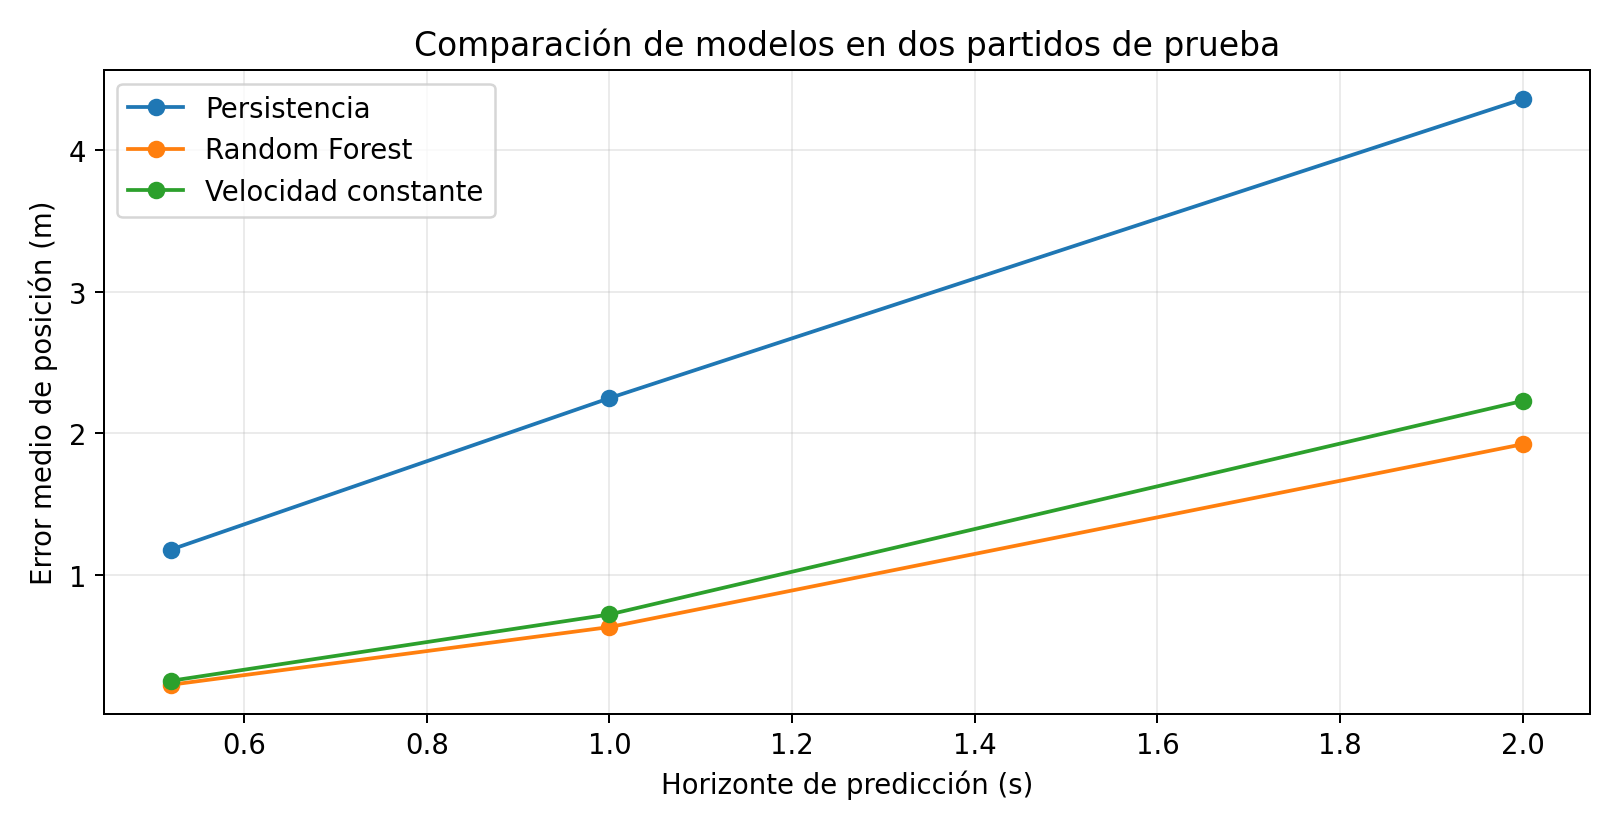

Importancia de características


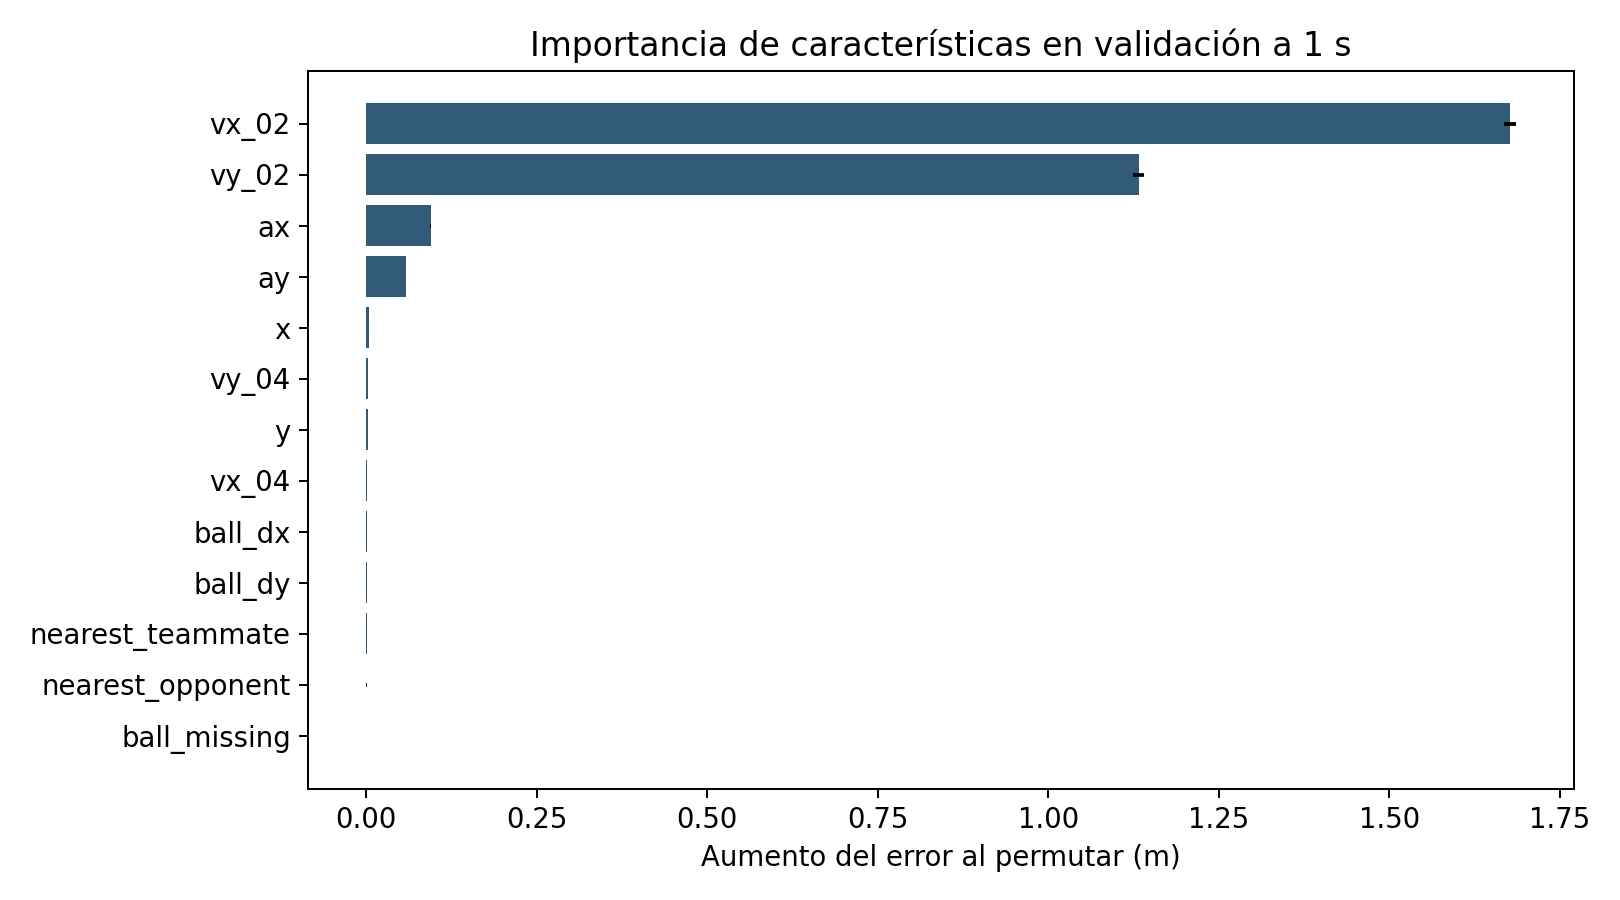

Generalización


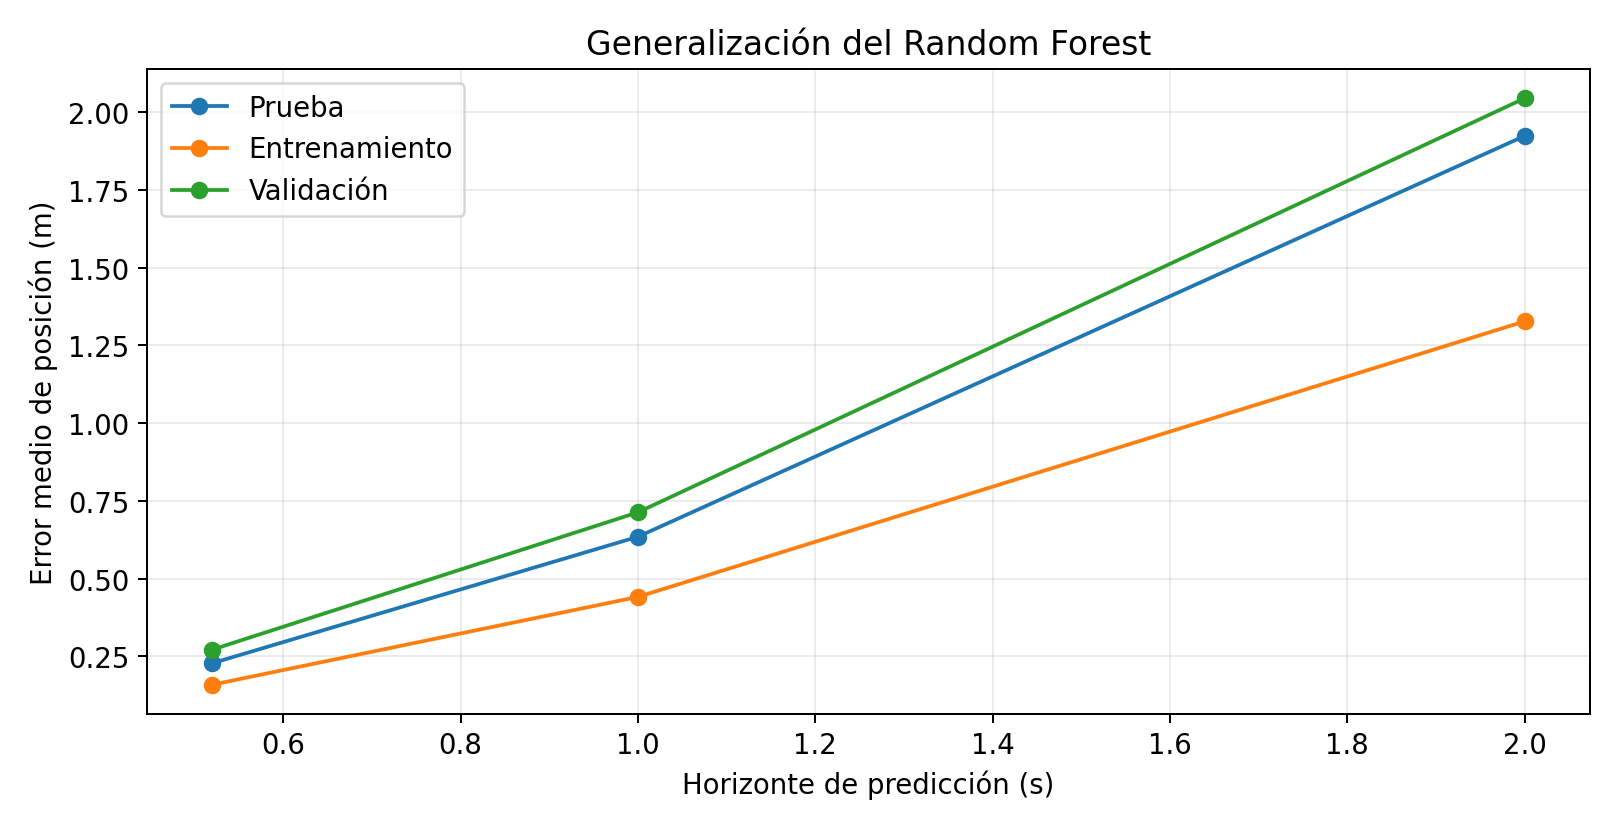

In [10]:
for titulo, nombre in [('Comparación de modelos', 'comparacion.png'), ('Importancia de características', 'importancia.png'), ('Generalización', 'ajuste.png')]:
    print(titulo)
    display(Image(filename=str(OUT / 'figuras' / nombre)))

In [11]:
reporte = json.loads((OUT / 'resultados.json').read_text(encoding='utf-8'))
print('Distribución de partidos:', reporte['splits'])
print('Ejemplos disponibles:', reporte['available_n'])
print('Ejemplos usados para entrenamiento:', reporte['train_used'])
print('Configuraciones elegidas:')
display(pd.DataFrame(reporte['selected']))
print('Ablación:')
display(pd.json_normalize(reporte['ablation']).round(4))

Distribución de partidos: {'train': ['2026-08-22_GENOA-NAPOLI', '2026-08-22_INTER-MONZA', '2026-08-22_PARMA-CAGLIARI', '2026-08-22_UDINESE-COMO', '2026-08-23_ATALANTA-SASSUOLO', '2026-08-23_FROSINONE-JUVENTUS'], 'validation': ['2026-08-23_TORINO-MILAN', '2026-08-23_VENEZIA-LECCE'], 'test': ['2026-08-24_BOLOGNA-LAZIO', '2026-08-24_ROMA-FIORENTINA']}
Ejemplos disponibles: {'train': 221248, 'validation': 70510, 'test': 64636}
Ejemplos usados para entrenamiento: 72000
Configuraciones elegidas:


,horizon_s,max_depth,min_samples_leaf,trees
0,0.52,20,5,80
1,1.00,20,5,80
2,2.00,20,5,80


Ablación:


,horizon_s,own_validation.mean_m,own_validation.median_m,own_validation.p90_m,own_validation.rmse_distance_m,own_validation.n,context_validation.mean_m,context_validation.median_m,context_validation.p90_m,context_validation.rmse_distance_m,context_validation.n
0,0.52,0.2728,0.1991,0.5661,0.3769,70510,0.2721,0.1982,0.5654,0.3761,70510
1,1.00,0.7171,0.5414,1.5029,0.9484,70510,0.7135,0.5391,1.4972,0.9444,70510
2,2.00,2.0598,1.6423,4.2105,2.6080,70510,2.0451,1.6281,4.1919,2.5924,70510


# 7. Conclusiones finales

## 7.1. ¿Qué algoritmo se eligió y por qué?

Para este primer modelo baseline elegimos **Random Forest Regressor**, ya que permite trabajar con relaciones no lineales entre las características de movimiento de los jugadores y sus desplazamientos futuros. Además, es un algoritmo relativamente sencillo de interpretar y nos permite identificar qué variables contribuyen más a las predicciones.

Para evaluar su desempeño, lo comparamos con dos modelos de referencia:

- **Persistencia:** supone que el jugador permanece en su posición actual.
- **Velocidad constante:** proyecta el movimiento del jugador a partir de su velocidad actual.

Los resultados obtenidos en el conjunto de prueba fueron los siguientes:

| Horizonte | Persistencia | Velocidad constante | Random Forest |
|---|---:|---:|---:|
| 0.52 segundos | 1.1812 m | 0.2563 m | **0.2284 m** |
| 1 segundo | 2.2489 m | 0.7239 m | **0.6350 m** |
| 2 segundos | 4.3572 m | 2.2294 m | **1.9240 m** |

Como podemos observar, Random Forest obtuvo el menor error en los tres horizontes. En particular, a un segundo consiguió reducir el error aproximadamente un **12.3 % respecto al modelo de velocidad constante**.

Esto nos indica que el algoritmo logra identificar patrones de movimiento que no pueden explicarse únicamente mediante una proyección lineal de la velocidad.

Por lo tanto, consideramos que Random Forest representa un punto de partida adecuado para nuestro proyecto, ya que establece un desempeño de referencia contra el cual podremos comparar modelos más complejos.

---

## 7.2. ¿Qué características resultaron más importantes?

A partir del análisis de importancia por permutación, encontramos que las características más relevantes fueron **`vx_02` y `vy_02`**, que representan componentes recientes de la velocidad del jugador en los ejes horizontal y vertical.

Estas dos variables mostraron una importancia considerablemente mayor que las demás. En segundo lugar aparecieron las componentes de aceleración, `ax` y `ay`, aunque con una contribución mucho menor.

Por otro lado, variables relacionadas con la posición del balón y las distancias al compañero u oponente más cercano presentaron una importancia relativamente baja.

Esto nos permite interpretar que, para predicciones de corto plazo, **el movimiento reciente del propio jugador es el principal determinante de su posición futura**.

Sin embargo, no necesariamente significa que las relaciones entre jugadores carezcan de importancia táctica. Más bien, consideramos que nuestro modelo actual todavía tiene una capacidad limitada para representar estas interacciones.

Este resultado es relevante para las siguientes etapas del proyecto, en las que podríamos incorporar modelos basados en grafos para representar explícitamente las relaciones espaciales y temporales entre jugadores.

---

## 7.3. ¿Existe sobreajuste o subajuste?

Para evaluar la capacidad de generalización del modelo, comparamos su desempeño en los conjuntos de entrenamiento, validación y prueba.

Los resultados de Random Forest fueron:

| Horizonte | Entrenamiento | Validación | Prueba |
|---|---:|---:|---:|
| 0.52 segundos | 0.1592 m | 0.2721 m | 0.2284 m |
| 1 segundo | 0.4416 m | 0.7135 m | 0.6350 m |
| 2 segundos | 1.3276 m | 2.0451 m | 1.9240 m |

Observamos que el error de entrenamiento es menor que el de validación y prueba en todos los horizontes.

Por ejemplo, a un segundo, el error aumenta de 0.4416 metros en entrenamiento a 0.7135 metros en validación.

Esto sugiere la presencia de **cierto grado de sobreajuste**, ya que el modelo tiene un mejor desempeño sobre las observaciones utilizadas durante su entrenamiento.

Sin embargo, también encontramos que el error de prueba es ligeramente inferior al de validación en los tres horizontes. Esto sugiere que, aunque existe una diferencia de generalización, el modelo conserva un desempeño competitivo en partidos que no fueron utilizados para entrenarlo.

Consideramos que los resultados son adecuados para un primer baseline, aunque todavía existe margen de mejora mediante ajustes de hiperparámetros, una mayor diversidad de partidos y nuevas características.

---

## 7.4. ¿Qué métrica es la más relevante para el problema?

Para evaluar nuestros modelos utilizamos principalmente el **error medio de posición euclidiano, expresado en metros**.

Esta métrica calcula la distancia entre la posición real de un jugador y la posición estimada por el modelo:

$$
E=\frac{1}{N}\sum_{i=1}^{N}
\sqrt{(x_i-\hat{x}_i)^2+(y_i-\hat{y}_i)^2}
$$

Donde:

- $N$ representa el número total de predicciones evaluadas.
- $(x_i,y_i)$ representa la posición real del jugador.
- $(\hat{x}_i,\hat{y}_i)$ representa la posición estimada por el modelo.

Consideramos que es la métrica más apropiada para nuestro proyecto porque permite interpretar directamente qué tan lejos se encuentra una predicción de la posición real del jugador.

Por ejemplo, cuando obtenemos un error de 0.635 metros a un segundo, podemos interpretar que las predicciones se encuentran, en promedio, a aproximadamente 64 centímetros de la posición real.

También utilizamos métricas complementarias, como la mediana, el percentil 90 y el RMSE de distancia, para analizar la distribución de los errores y detectar predicciones particularmente imprecisas.

Elegimos el error medio euclidiano como métrica principal porque resulta intuitivo, es comparable entre modelos y tiene una interpretación directa en el contexto del fútbol.

---

## 7.5. ¿Cuál es el desempeño mínimo aceptable?

Para establecer un desempeño mínimo, consideramos que nuestro modelo debe superar al menos al método de velocidad constante, ya que este representa una referencia sencilla pero competitiva para predecir movimientos a corto plazo.

Los errores obtenidos por velocidad constante en el conjunto de prueba fueron:

- **0.2563 metros** a 0.52 segundos.
- **0.7239 metros** a un segundo.
- **2.2294 metros** a dos segundos.

Por lo tanto, proponemos utilizar estos valores como umbrales iniciales de referencia: cualquier modelo más avanzado debería conseguir errores inferiores en los mismos partidos y horizontes de predicción.

Nuestro Random Forest cumple con este criterio en los tres horizontes evaluados.

No obstante, reconocemos que superar la velocidad constante no garantiza que las predicciones sean suficientemente precisas para cualquier aplicación táctica.

Por ello, estos valores representan **criterios iniciales de comparación y no umbrales definitivos de utilidad deportiva**. Estos últimos deberán definirse posteriormente con el equipo y los asesores del proyecto, considerando las aplicaciones específicas que se quieran desarrollar.

---

## 7.6. Conclusión general del Avance 3

Con este avance logramos desarrollar y evaluar un primer modelo baseline para la predicción de movimientos de jugadores de fútbol a partir de datos de seguimiento de diez partidos de la Serie A italiana.

Durante el proceso construimos características relacionadas con la posición, velocidad, aceleración y contexto espacial de los jugadores. Posteriormente, entrenamos modelos Random Forest para anticipar sus desplazamientos a 0.52, 1 y 2 segundos, utilizando una separación por partidos para evitar que observaciones del mismo encuentro aparecieran en diferentes conjuntos de entrenamiento y evaluación.

Los resultados muestran que Random Forest supera consistentemente a los modelos de persistencia y velocidad constante. Sin embargo, también encontramos que el error aumenta conforme se amplía el horizonte de predicción y que las variables relacionadas con la velocidad reciente tienen una influencia considerablemente mayor que las características de contexto.

Esto nos lleva a considerar que **el baseline es capaz de aprender patrones de movimiento individuales, pero todavía no representa de manera explícita las relaciones tácticas entre los jugadores**.

En las siguientes etapas del proyecto buscaremos explorar arquitecturas que permitan incorporar estas interacciones, particularmente modelos basados en grafos y enfoques temporales, para avanzar de la predicción individual de posiciones hacia una mejor comprensión del comportamiento colectivo de los equipos.

Finalmente, consideramos que este avance cumple con su propósito principal: **establecer una referencia cuantitativa, reproducible y comparable para evaluar el desempeño de los modelos que desarrollaremos posteriormente**.
